# Assignment 3: Student dropout — combined binary analysis

> How can machine learning use student background information and academic results from the first two semesters to identify students at risk of dropping out and help academic advisors prioritize support at the end of the first academic year?

This notebook combines the strongest ideas from `assignment3_student_dropout.ipynb` and `assignment_3.ipynb` in a fresh, reproducible experiment. The report follows assignment sections 1–10 and is written in English.

**Main design:** binary `Dropout` versus `Graduate`; unresolved `Enrolled` records excluded; two administrative variables excluded because their recording time is unverified; feature-engineering and feature-selection ablations; KNN, tree and SVM baselines; tree bagging, AdaBoost and gradient boosting; cross-course weight transfer; a tuned deep network; development-selected F2 thresholds; fixed-capacity ranking; probability calibration; subgroup diagnostics; and measured computation costs.

All tables and figures below are generated by running this notebook. Original notebooks and CSV are unchanged. Results apply to the resolved-outcome subset, not to all currently active students.

**Local sources:** [assignment PDF](IT3212-2026-Assignment%203.pdf) and [student dataset](Student-graduation/graduation_dataset.csv).

**Run:** select the project's `.venv` Python interpreter and run all cells from this directory. Required analysis packages: `numpy pandas scikit-learn matplotlib threadpoolctl`.

## 1. Develop a problem statement (real world and machine learning)

### 1.1 Real-world problem

Student dropout is a challenge for higher education institutions. Academic advisors have limited time and resources, making it difficult to determine which students should receive support first. Student background information and academic results from the first two semesters may provide useful indicators of dropout risk.

The aim of this project is to investigate whether machine learning can use this information to identify students at risk of dropping out and help academic advisors prioritize support at the end of the first academic year. The intended users are academic advisors, and the intended output is a ranking of students by estimated dropout risk to inform follow-up decisions.

### 1.2 Machine learning problem

This project approaches dropout prediction as a supervised classification problem. Each observation represents a student. Input features include student background information and academic results from the first two semesters. The dataset's target column, `Target`, contains the outcomes `Dropout`, `Graduate`, and `Enrolled`.

Dropout is the outcome of primary interest. Section 2 defines the implemented binary task as `Dropout = 1` versus `Graduate = 0`, with `Enrolled` retained separately because its final outcome is unresolved. The evaluation population therefore consists of students with known final outcomes.

We will compare classification models and assess their ability to identify students associated with dropout. Where model scores support ranking, we will also examine how they could help advisors prioritize a limited number of students for follow-up. Scores will only be interpreted as dropout probabilities if their calibration supports this interpretation.

### 1.3 Connection between the real-world and machine learning problems

The practical decision is which students should receive support first. A model can support this decision by ranking students according to estimated risk. Evaluation must therefore consider both the proportion of dropout cases identified (recall) and the proportion of flagged students who are dropout cases (precision). We will also consider performance among the highest-ranked students under an explicitly stated support-capacity assumption.

The project evaluates prediction and prioritization. It does not establish that an intervention causes a reduction in dropout.

### 1.4 Prediction time, scope, and limitations

The intended prediction time is the end of the first academic year, after results from the first two semesters are available. The intended population consists of students who are still active at that point. Only information available by that time should be used as input.

The local CSV does not include an explicit dropout date. We must investigate the dataset documentation to determine whether `Dropout` includes students who left before the end of the first academic year and when other variables were recorded. Otherwise, semester results may reflect an event that has already occurred rather than predict future dropout.

If this timing cannot be established, the empirical results must be described as classification of recorded student outcomes using first-year information. Their applicability to predicting future dropout among students still active at the end of year one will remain a limitation.

### 1.5 Decisions to document before modelling

- Confirm the meaning and recording time of the target and input variables using dataset documentation.
- Define the prediction population and justify the treatment of `Enrolled`.
- Specify the classification target and positive class.
- Define evaluation measures and an explicit assumption about advisors' follow-up capacity.

Section 2 documents the binary target, treatment of unresolved outcomes, and data split. Sections 3-10 implement model development and evaluation, using average precision for selection and an assumed 20% advisor capacity for prioritization. Recording-time verification remains unresolved.

## 2. Implement preprocessing and justify the preprocessing steps

This section loads and validates the local dataset, defines a binary target, splits the data, and implements reusable preprocessing. Feature engineering, feature selection, and model training are reserved for the later assignment sections.

### 2.1 Setup and reproducibility

Run the notebook from top to bottom using a Python kernel with `numpy`, `pandas`, and `scikit-learn` installed. The setup below records package versions and fixes the random seed. The original CSV is read without modification. If the kernel lacks these packages, run `%pip install numpy pandas scikit-learn` in a temporary notebook cell and restart the kernel before running all cells.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
DATA_PATH = Path("Student-graduation") / "graduation_dataset.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError("Run this notebook from the assignment folder containing Student-graduation/.")

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.7
NumPy: 2.5.4
pandas: 3.1.0
scikit-learn: 1.9.1


### 2.2 Load and inspect the data

We inspect shape, target counts, missing values, duplicate rows, and data types before transforming the data. These are data-integrity checks; associations with the target and model-driven decisions will be investigated using training data only.

`utf-8-sig` removes a possible byte-order mark from the first column name. The source spelling `Nacionality` is preserved so that column names remain traceable to the CSV.

In [2]:
df_raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
assert df_raw.columns.is_unique, "Duplicate column names must be resolved."
assert "Target" in df_raw.columns

expected_targets = {"Dropout", "Graduate", "Enrolled"}
assert set(df_raw["Target"].dropna().unique()) == expected_targets

quality_summary = pd.Series({
    "Rows": len(df_raw),
    "Predictors": df_raw.shape[1] - 1,
    "Missing cells": int(df_raw.isna().sum().sum()),
    "Duplicate rows": int(df_raw.duplicated().sum()),
}, name="Value")
display(quality_summary.to_frame())
display(df_raw.head())
display(df_raw["Target"].value_counts().rename_axis("Recorded outcome").to_frame("Students"))
display(pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing": df_raw.isna().sum(),
    "distinct_values": df_raw.nunique(),
}))

,Value
Rows,4424
Predictors,34
Missing cells,0
Duplicate rows,0


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


,Students
Recorded outcome,
Graduate,2209
Dropout,1421
Enrolled,794


,dtype,missing,distinct_values
Marital status,int64,0,6
Application mode,int64,0,18
Application order,int64,0,8
Course,int64,0,17
Daytime/evening attendance,int64,0,2
Previous qualification,int64,0,17
Nacionality,int64,0,21
Mother's qualification,int64,0,29
Father's qualification,int64,0,34
Mother's occupation,int64,0,32


### 2.3 Define the target and modelling population

We use **binary classification**, with `Dropout = 1` (the positive class) and `Graduate = 0`. Students labelled `Enrolled` are set aside because they have not yet reached a resolved final outcome. Treating them as confirmed non-dropouts could introduce incorrect labels. Their rows are retained separately, not deleted from the source.

This defines a comparison of dropout versus graduation among students with known final outcomes. Excluding unresolved outcomes changes the population; performance on this subset must not be presented as validated performance for all currently enrolled students.

The [UCI dataset description](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success) describes outcomes at the end of the normal course duration and information from enrollment and the first two semesters. The local file has 34 predictors, whereas the UCI version lists 36, so the local schema and category codes are treated as authoritative for this implementation. We do not assume UCI code-to-label mappings apply to this local version.

**Timing limitation:** the CSV does not establish when dropout occurred or provide a date for each administrative observation. We exclude `Debtor` and `Tuition fees up to date` from every experiment because their recording time is unverified. This is an a priori availability restriction, not outcome-based feature selection. The remaining variables are provisionally retained; excluding these two fields does not resolve the broader absence of timestamps. We cannot filter to students demonstrably still active at the prediction time and do not use zero semester results as a substitute for dropout dates.

In [3]:
df_unresolved = df_raw.loc[df_raw["Target"].eq("Enrolled")].copy()
df_model = df_raw.loc[df_raw["Target"].isin(["Dropout", "Graduate"])].copy()

EXCLUDED_FOR_TIMING = ["Debtor", "Tuition fees up to date"]
X = df_model.drop(columns=["Target"] + EXCLUDED_FOR_TIMING)
y = df_model["Target"].map({"Graduate": 0, "Dropout": 1}).astype("int64")
y.name = "Dropout"

assert "Target" not in X.columns
assert len(X) + len(df_unresolved) == len(df_raw)
assert set(y.unique()) == {0, 1}
print(f"Resolved outcomes used for modelling: {len(X):,}")
print(f"Unresolved outcomes set aside: {len(df_unresolved):,}")
display(pd.DataFrame({"Students": y.value_counts().sort_index(),
                      "Share": y.value_counts(normalize=True).sort_index()})
        .rename_axis("Dropout (0 = Graduate, 1 = Dropout)"))
print("Predictors retained:", X.shape[1], "; excluded for uncertain timing:", EXCLUDED_FOR_TIMING)
assert X.shape == (3630, 32)
assert len(df_unresolved) == 794
assert not set(EXCLUDED_FOR_TIMING).intersection(X.columns)

Resolved outcomes used for modelling: 3,630
Unresolved outcomes set aside: 794


,Students,Share
"Dropout (0 = Graduate, 1 = Dropout)",,
0,2209,0.60854
1,1421,0.39146


Predictors retained: 32 ; excluded for uncertain timing: ['Debtor', 'Tuition fees up to date']


### 2.4 Specify variable types and validate values

Numeric storage does not make a category code a measurement. For example, course code 10 is not quantitatively twice course code 5. We therefore explicitly separate:

- **Nominal categories:** marital status, application mode, course, previous qualification, nationality, and parents' qualification/occupation. We do not infer an educational ranking from the supplied codes.
- **Binary indicators:** the six retained 0/1 variables (the other two are excluded for uncertain timing). Both values are retained as supplied; no undocumented code-to-label meanings are assigned.
- **Numeric variables:** application preference order, age, semester counts and grades, and the three economic indicators. Application order is treated as an ordered numeric predictor; equal spacing is a modelling assumption. Economic indicators are retained as supplied context, with any later selection handled in section 4.

We check finite values, binary coding, non-negative counts, integer-valued codes/counts, and grades within 0-20. Negative inflation and GDP values are allowed. Unusual but plausible observations, including older students and high evaluation counts, are not removed merely because they are extreme. Evaluation counts are not assumed to be unique enrolled units.

Zero semester grades and counts are retained. The CSV alone does not justify replacing them with missing values: a zero can carry information about academic activity. Distinguishing non-participation from missing records requires further documentation.

In [4]:
nominal_features = [
    "Marital status", "Application mode", "Course", "Previous qualification",
    "Nacionality", "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation",
]
binary_features = [
    "Daytime/evening attendance", "Displaced", "Educational special needs",
    "Gender", "Scholarship holder", "International",
]
academic_features = [c for c in X.columns if c.startswith("Curricular units")]
grade_features = [c for c in academic_features if c.endswith("(grade)")]
count_features = [c for c in academic_features if c not in grade_features]
numeric_features = ["Application order", "Age at enrollment"] + academic_features + [
    "Unemployment rate", "Inflation rate", "GDP",
]

assigned_features = nominal_features + binary_features + numeric_features
assert len(assigned_features) == len(set(assigned_features)), "A feature was assigned twice."
assert set(assigned_features) == set(X.columns), "Review unexpected or missing predictors."

# Fail explicitly rather than silently imputing or dropping unexpected records.
all_predictors = df_raw.drop(columns="Target")
assert not df_raw.isna().any().any(), "Missing data found; revise and justify an imputation strategy."
assert np.isfinite(all_predictors.to_numpy(dtype=float)).all(), "Non-finite predictor found."
assert not df_raw.duplicated().any(), "Duplicate records found; investigate their provenance."
for col in binary_features + EXCLUDED_FOR_TIMING:
    assert set(all_predictors[col].unique()).issubset({0, 1}), col
for col in nominal_features + binary_features + count_features + ["Application order", "Age at enrollment"]:
    assert np.equal(all_predictors[col], np.floor(all_predictors[col])).all(), col
assert all_predictors[count_features + ["Application order", "Age at enrollment"]].ge(0).all().all()
assert all_predictors[grade_features].ge(0).all().all()
assert all_predictors[grade_features].le(20).all().all()

display(pd.DataFrame({
    "Group": ["Nominal", "Binary", "Numeric"],
    "Number of predictors": [len(nominal_features), len(binary_features), len(numeric_features)],
}))
print("All integrity checks passed. No rows were removed for missing values or outliers.")

,Group,Number of predictors
0,Nominal,9
1,Binary,6
2,Numeric,17


All integrity checks passed. No rows were removed for missing values or outliers.


### 2.5 Create the training and held-out test sets

We reserve 20% of the resolved-outcome data as a final test set. Stratification approximately preserves the dropout proportion, and a fixed seed makes the split reproducible. The original row indices are retained to check that the sets do not overlap.

The remaining 80% is used for development with five-fold stratified cross-validation. Feature selection, learned preprocessing, hyperparameter tuning, and threshold choices must be performed within the training data. The final test set will be used for final evaluation only.

A random split is used because the local file has no explicit cohort/date or student identifier. It cannot demonstrate generalization to a later cohort, nor can it verify that different rows never represent the same student. A temporal or grouped split would be preferable if the required identifiers became available.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE,
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

assert set(X_train.index).isdisjoint(X_test.index)
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
assert len(X_train) + len(X_test) == len(X)

display(pd.DataFrame({
    "Students": [len(X_train), len(X_test)],
    "Dropout count": [int(y_train.sum()), int(y_test.sum())],
    "Dropout share": [y_train.mean(), y_test.mean()],
}, index=["Training / cross-validation", "Held-out test"]))

,Students,Dropout count,Dropout share
Training / cross-validation,2904,1137,0.391529
Held-out test,726,284,0.391185


### 2.6 Implement reusable preprocessing

| Step | Choice | Justification |
| --- | --- | --- |
| Missing values | No imputation on this file | The integrity checks require no missing cells. Imputation would add no benefit here. Unexpected missingness triggers an explicit review. |
| Nominal categories | One-hot encoding | Avoids imposing an artificial order or distance between category codes. All observed training categories are retained. |
| Unseen categories | `handle_unknown="ignore"` | Allows validation/test or future data to contain a category absent from training. Its indicator block is all zero; its effect is not learned. |
| Numeric variables | Standardization using training means and standard deviations | Prevents large-scale measurements from dominating distance-based methods, SVMs, and neural-network optimization. |
| Binary variables | Pass through as 0/1 | Already consistently coded and do not need nominal expansion. |
| Outliers and zeros | Retain valid supplied observations | Avoids discarding potentially meaningful students or assuming zero means missing. |
| Class imbalance | Preserve observed class frequencies | No resampling is required for preprocessing. Decision thresholds are selected using training out-of-fold scores only; no class-weight search is included in this bounded experiment. |

We keep dense numeric output because this dataset is small and the same representation can be consumed by the planned model families. Category vocabularies and scaling parameters are learned only when the transformer is fitted. No feature engineering or feature selection is performed here.

`preprocessor` is deliberately left **unfitted**. Later sections should use `Pipeline([("preprocessing", clone(preprocessor)), ("model", estimator)])` with raw `X_train` and `cv`. Scikit-learn then fits the transformations separately inside each training fold. This prevents validation information from influencing scaling or category discovery. See the [scikit-learn guidance on leakage and pipelines](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

In [6]:
preprocessor = ColumnTransformer(
    transformers=[
        ("nominal", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_features),
        ("numeric", StandardScaler(), numeric_features),
        ("binary", "passthrough", binary_features),
    ],
    remainder="drop",
    verbose_feature_names_out=True,
)

# A separate fitted copy demonstrates the transformation on training data only.
# Do not pass this globally transformed array to cross-validation.
preprocessing_preview = clone(preprocessor)
X_train_preview = preprocessing_preview.fit_transform(X_train)
transformed_feature_names = preprocessing_preview.get_feature_names_out()

assert X_train_preview.shape[0] == len(X_train)
assert X_train_preview.shape[1] == len(transformed_feature_names)
assert np.isfinite(X_train_preview).all()
assert not hasattr(preprocessor, "transformers_"), "Keep the reusable template unfitted."

print("Original training shape:", X_train.shape)
print("Transformed training shape:", X_train_preview.shape)
display(pd.DataFrame(
    X_train_preview[:5], columns=transformed_feature_names, index=X_train.index[:5],
).iloc[:, :12])

# Check the promised behavior for a category not seen during fitting.
unseen_example = X_train.iloc[[0]].copy()
example_column = nominal_features[0]
unseen_example[example_column] = X_train[example_column].max() + 1
unseen_output = preprocessing_preview.transform(unseen_example)
assert unseen_output.shape[1] == X_train_preview.shape[1]
assert np.isfinite(unseen_output).all()
print("Unseen-category transformation passed. The held-out test data has not been transformed or scored.")

Original training shape: (2904, 32)
Transformed training shape: (2904, 223)


,nominal__Marital status_1,nominal__Marital status_2,nominal__Marital status_3,nominal__Marital status_4,nominal__Marital status_5,nominal__Marital status_6,nominal__Application mode_1,nominal__Application mode_2,nominal__Application mode_3,nominal__Application mode_4,nominal__Application mode_5,nominal__Application mode_6
949,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1301,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1740,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
877,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2002,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Unseen-category transformation passed. The held-out test data has not been transformed or scored.


### 2.7 Summary and hand-off to section 3

The preprocessing code is complete and can be rerun from the raw CSV. The executed outputs above report the data-quality checks, target population, split sizes, variable groups, and transformed training dimensions.

The objects for subsequent sections are:

- `X_train`, `y_train`: raw development data for feature engineering and modelling.
- `X_test`, `y_test`: held-out raw test data for final evaluation.
- `preprocessor`: an unfitted transformer template to place inside model pipelines.
- `cv`: the reproducible five-fold stratified cross-validation strategy.
- `df_unresolved`: students with unresolved outcomes, excluded from supervised evaluation.

`preprocessing_preview` and `X_train_preview` are demonstrations only. They must not be used as pre-fitted inputs to cross-validation. No classifier has been trained in this section. The target/timing limitations in section 2.3 remain applicable.

## 3. Extract features and justify the methods used

### 3.1 Domain-informed feature engineering

Raw semester counts depend on course load. We add rates to express progress relative to enrollment, totals to describe first-year progress, and changes to represent improvement or deterioration. The following transformations use only each student's supplied first-year observations; they do not learn from outcomes or other rows.

| Derived feature | Definition | Reason |
| --- | --- | --- |
| Pass rate, each semester | Approved / enrolled | Distinguishes low success from simply taking fewer units. |
| No-enrollment indicator, each semester | 1 if enrolled = 0 | Separates an undefined rate from an observed zero pass rate. |
| First-year approved | Approved in semester 1 + semester 2 | Measures accumulated academic progress. |
| First-year pass rate | Total approved / total enrolled | Summarizes success relative to the full first-year load. |
| Grade change | Grade in semester 2 minus semester 1 | Represents the direction of academic performance. |
| Pass-rate change | Semester 2 rate minus semester 1 rate | Represents improvement relative to course load. |
| No-evaluation rate, each semester | Units without evaluation / enrolled | Describes inactivity relative to workload. |
| Approved-unit change | Approved in semester 2 minus semester 1 | Describes change in completed workload. |

This produces **11 derived features**. Rates are not clipped: administrative counts can have definitions that require checking before imposing further restrictions.

For a zero denominator, a rate is explicitly set to zero and paired with the no-enrollment indicator(s). This is a defined representation, not a claim that the student failed all enrolled units. Grade changes involving a zero retain the source ambiguity discussed in section 2. Credited units and evaluation attempts are not treated as interchangeable with enrolled units.

A custom transformer keeps these operations inside each modelling pipeline and preserves the original columns. The test data is not used to choose formulas.

In [7]:
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin
from sklearn.feature_selection import SelectPercentile, VarianceThreshold, f_classif
from sklearn.model_selection import GridSearchCV, cross_validate, cross_val_predict
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
    recall_score, f1_score, fbeta_score, accuracy_score, balanced_accuracy_score,
    precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay,
    PrecisionRecallDisplay, RocCurveDisplay)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
from time import perf_counter
import warnings
import math
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

DERIVED_FEATURES = ["pass_rate_s1", "no_enrollment_s1", "pass_rate_s2", "no_enrollment_s2",
                    "approved_year1", "pass_rate_year1", "grade_change", "pass_rate_change",
                    "no_evaluation_rate_s1", "no_evaluation_rate_s2", "approved_change"]

class AcademicFeatureEngineer(TransformerMixin, BaseEstimator):
    def fit(self, X, y=None):
        self.n_features_in_ = X.shape[1]
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        out = X.copy()
        def safe_rate(numerator, denominator):
            return np.divide(numerator.to_numpy(dtype=float), denominator.to_numpy(dtype=float),
                             out=np.zeros(len(out), dtype=float), where=denominator.to_numpy() != 0)
        for sem in (1, 2):
            suffix = "1st" if sem == 1 else "2nd"
            approved = out[f"Curricular units {suffix} sem (approved)"]
            enrolled = out[f"Curricular units {suffix} sem (enrolled)"]
            out[f"pass_rate_s{sem}"] = safe_rate(approved, enrolled)
            out[f"no_enrollment_s{sem}"] = enrolled.eq(0).astype(int)
            out[f"no_evaluation_rate_s{sem}"] = safe_rate(out[f"Curricular units {suffix} sem (without evaluations)"], enrolled)
        approved_total = out["Curricular units 1st sem (approved)"] + out["Curricular units 2nd sem (approved)"]
        enrolled_total = out["Curricular units 1st sem (enrolled)"] + out["Curricular units 2nd sem (enrolled)"]
        out["approved_year1"] = approved_total
        out["approved_change"] = out["Curricular units 2nd sem (approved)"] - out["Curricular units 1st sem (approved)"]
        out["pass_rate_year1"] = safe_rate(approved_total, enrolled_total)
        out["grade_change"] = out["Curricular units 2nd sem (grade)"] - out["Curricular units 1st sem (grade)"]
        out["pass_rate_change"] = out["pass_rate_s2"] - out["pass_rate_s1"]
        return out

    def get_feature_names_out(self, input_features=None):
        original = self.feature_names_in_ if input_features is None else np.asarray(input_features)
        return np.concatenate([original, np.asarray(DERIVED_FEATURES)])

engineered_preview = AcademicFeatureEngineer().fit_transform(X_train)
assert len(engineered_preview) == len(X_train)
assert np.isfinite(engineered_preview[DERIVED_FEATURES].to_numpy()).all()
display(engineered_preview[DERIVED_FEATURES].head())

engineered_numeric = numeric_features + [c for c in DERIVED_FEATURES if not c.startswith("no_enrollment")]
engineered_binary = binary_features + ["no_enrollment_s1", "no_enrollment_s2"]

def make_preprocessor(engineered=True):
    return ColumnTransformer([
        ("nominal", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_features),
        ("numeric", StandardScaler(), engineered_numeric if engineered else numeric_features),
        ("binary", "passthrough", engineered_binary if engineered else binary_features),
    ], verbose_feature_names_out=True)

def make_model_pipeline(estimator, engineered=True, percentile=75):
    return Pipeline([
        ("features", AcademicFeatureEngineer() if engineered else "passthrough"),
        ("preprocessing", make_preprocessor(engineered)),
        ("constant_filter", VarianceThreshold()),
        ("selection", SelectPercentile(f_classif, percentile=percentile)),
        ("model", estimator),
    ])

,pass_rate_s1,no_enrollment_s1,pass_rate_s2,no_enrollment_s2,approved_year1,pass_rate_year1,grade_change,pass_rate_change,no_evaluation_rate_s1,no_evaluation_rate_s2,approved_change
949,0.000000,0,0.000000,0,0,0.000000,0.000000,0.000000,0.0,0.0,0
1301,0.000000,0,0.000000,0,0,0.000000,0.000000,0.000000,0.0,0.0,0
1740,0.833333,0,0.500000,0,8,0.666667,-0.933333,-0.333333,0.0,0.0,-2
877,0.285714,0,0.000000,0,2,0.142857,-10.000000,-0.285714,0.0,0.0,-2
2002,1.000000,0,0.833333,0,11,0.916667,-0.257143,-0.166667,0.0,0.0,-1


### 3.2 Training-only ablation

To assess whether these features help, we compare the same depth-limited decision tree with and without feature engineering, keeping all nonconstant encoded features. Five identical stratified folds are used. Average precision (AP) summarizes precision-recall ranking performance; it is our primary model-selection metric because the positive class is dropout and both finding cases and limiting false alerts matter. AP is a particular summary of the precision-recall curve, not trapezoidal PR-AUC.

This is a development experiment, not an unbiased estimate for whichever configuration wins. No formulas are revised based on held-out test outcomes.

In [8]:
ablation_rows = []
for engineered in (False, True):
    pipeline = make_model_pipeline(DecisionTreeClassifier(max_depth=5, min_samples_leaf=10,
                                   random_state=RANDOM_STATE), engineered=engineered, percentile=100)
    with threadpool_limits(limits=1):
        scores = cross_validate(pipeline, X_train, y_train, cv=cv,
                                scoring="average_precision", n_jobs=1)
    ablation_rows.append({"Features": "Original + engineered" if engineered else "Original only",
                         "Mean CV AP": scores["test_score"].mean(),
                         "Fold SD": scores["test_score"].std(ddof=1)})
feature_ablation = pd.DataFrame(ablation_rows)
display(feature_ablation.round(4))
delta = feature_ablation.loc[1, "Mean CV AP"] - feature_ablation.loc[0, "Mean CV AP"]
print(f"Adding the engineered features changes tree development AP by {delta:+.4f}.")
print("This single-model ablation does not establish an improvement for every algorithm.")

,Features,Mean CV AP,Fold SD
0,Original only,0.8951,0.0145
1,Original + engineered,0.9132,0.0125


Adding the engineered features changes tree development AP by +0.0181.
This single-model ablation does not establish an improvement for every algorithm.


## 4. Select features or use dimensionality reduction and justify the methods

### 4.1 Remove constant columns and rank features

One-hot encoding creates many predictors, some of which may be rare or constant in a fold. `VarianceThreshold` first removes constant columns. `SelectPercentile(f_classif)` then ranks the remaining columns by their univariate association with the binary outcome and retains a chosen percentage.

This filter is computationally inexpensive, works after encoding, and preserves named predictors for interpretation. Unlike PCA, it does not mix multiple variables into unnamed components. Its limitations are that correlated features can be redundant and features useful only through interactions can be discarded. ANOVA F-scores are used for ranking, not as causal evidence or corrected hypothesis tests.

We compare 50%, 75%, and 100% retention with a fixed decision tree. Later model searches explicitly compare 75% against 100% where specified, allowing different algorithms to retain all features if selection is unhelpful. The 75% preview below only illustrates the ranking. Both filters are fitted inside training folds during model selection; the preview is never reused in validation.

In [9]:
selection_rows = []
for percentile in (50, 75, 100):
    candidate = make_model_pipeline(DecisionTreeClassifier(max_depth=5, min_samples_leaf=10,
                                    random_state=RANDOM_STATE), percentile=percentile)
    with threadpool_limits(limits=1):
        scores = cross_validate(candidate, X_train, y_train, cv=cv,
                                scoring="average_precision", n_jobs=1)
    selection_rows.append({"Retained percentile": percentile,
                           "Mean CV AP": scores["test_score"].mean(),
                           "Fold SD": scores["test_score"].std(ddof=1)})
selection_comparison = pd.DataFrame(selection_rows)
display(selection_comparison.round(4))

selection_preview = make_model_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE))[:-1]
selection_preview.fit(X_train, y_train)
encoded_names = selection_preview.named_steps["preprocessing"].get_feature_names_out()
nonconstant_names = encoded_names[selection_preview.named_steps["constant_filter"].get_support()]
selector = selection_preview.named_steps["selection"]
feature_ranking = pd.DataFrame({"Feature": nonconstant_names, "F-score": selector.scores_,
                               "Selected in preview": selector.get_support()})
print(f"Preview: {len(encoded_names)} encoded columns -> {len(nonconstant_names)} nonconstant -> {selector.get_support().sum()} selected.")
display(feature_ranking.sort_values("F-score", ascending=False).head(15).round(2))
print("Selection-development comparison leader:",
      int(selection_comparison.loc[selection_comparison["Mean CV AP"].idxmax(), "Retained percentile"]), "%")

,Retained percentile,Mean CV AP,Fold SD
0,50,0.9141,0.0095
1,75,0.9147,0.0124
2,100,0.9132,0.0125


Preview: 234 encoded columns -> 234 nonconstant -> 175 selected.


,Feature,F-score,Selected in preview
218,numeric__pass_rate_s2,3429.06,True
220,numeric__pass_rate_year1,3167.54,True
217,numeric__pass_rate_s1,2359.79,True
211,numeric__Curricular units 2nd sem (approved),2152.68,True
219,numeric__approved_year1,1775.58,True
212,numeric__Curricular units 2nd sem (grade),1708.28,True
205,numeric__Curricular units 1st sem (approved),1287.56,True
206,numeric__Curricular units 1st sem (grade),1073.49,True
230,binary__Scholarship holder,334.81,True
201,numeric__Age at enrollment,213.17,True


Selection-development comparison leader: 75 %


## 5. Implement three algorithms and justify the choice

### 5.1 Algorithms and bounded hyperparameter searches

| Algorithm | Why it fits this problem | Tuned parameters |
| --- | --- | --- |
| K-nearest neighbours | A local similarity baseline with nonlinear boundaries; useful for testing whether similar student profiles have similar outcomes. Scaling is essential, and many one-hot columns can make distances less informative. | Neighbours 11/31; uniform/distance weighting; 75%/100% features. |
| Decision tree | Captures nonlinear thresholds and interactions, and can be inspected as rules for academic progress. An unconstrained tree can overfit. | Depth 4/8; minimum leaf size 5/20; 75%/100% features. |
| SVM with RBF kernel | Learns a smooth nonlinear boundary in the mixed background/academic feature space. Scaling and regularization matter. | C 0.5/2; gamma `scale`/0.01; 75%/100% features. |

A constant-prior `DummyClassifier` provides a no-information baseline. For the SVM, `decision_function` supplies ranking scores; these are not probabilities. We avoid adding expensive probability fitting when ranking is the main purpose.

The primary search metric is **AP**, and every model uses the same five folds and outer train/test split. ROC-AUC and binary metrics are reported alongside AP. Search ranges are deliberately small to keep the notebook reproducible on a CPU; they are not exhaustive. Each search fits every candidate in five folds and then refits the best candidate on all training data. Timing includes preprocessing and selection. CPU thread counts are restricted for more stable timing.

**Evaluation protocol:** all model choices are based on development CV. Selected-model CV scores and subsequent out-of-fold scores reuse the tuning data and can be optimistic; they are not nested-CV estimates. The untouched test set is evaluated once in section 10, after all models and operational rules have been fixed.

In [10]:
searches = {}
fitted_models = {}
search_records = []
SCORING = {"AP": "average_precision", "ROC_AUC": "roc_auc", "F1": "f1"}

def run_search(name, pipeline, grid):
    search = GridSearchCV(pipeline, grid, scoring=SCORING, refit="AP", cv=cv,
                          n_jobs=1, error_score="raise", return_train_score=False)
    start = perf_counter()
    with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        search.fit(X_train, y_train)
    elapsed = perf_counter() - start
    convergence_count = sum(issubclass(w.category, ConvergenceWarning) for w in caught)
    other_warnings = sorted({str(w.message) for w in caught if not issubclass(w.category, ConvergenceWarning)})
    best = search.best_index_
    record = {"Model": name, "CV AP": search.best_score_,
              "Fold SD": search.cv_results_["std_test_AP"][best],
              "CV ROC-AUC": search.cv_results_["mean_test_ROC_AUC"][best],
              "Search seconds": elapsed, "Refit seconds": search.refit_time_,
              "Candidates": len(search.cv_results_["params"]),
              "Convergence warnings": convergence_count}
    searches[name] = search
    fitted_models[name] = search.best_estimator_
    search_records.append(record)
    print(f"{name}: CV AP={search.best_score_:.4f}, {elapsed:.1f}s; best={search.best_params_}")
    if convergence_count:
        print(f"  {convergence_count} iteration-limit warnings: convergence was not established in all fits.")
    for warning in other_warnings:
        print("  Warning:", warning)
    return search

basic_specs = {
    "KNN": (KNeighborsClassifier(), {"model__n_neighbors": [11, 31],
             "model__weights": ["uniform", "distance"], "selection__percentile": [75, 100]}),
    "Decision tree": (DecisionTreeClassifier(random_state=RANDOM_STATE),
             {"model__max_depth": [4, 8], "model__min_samples_leaf": [5, 20],
              "selection__percentile": [75, 100]}),
    "RBF SVM": (SVC(kernel="rbf", probability=False, random_state=RANDOM_STATE),
             {"model__C": [0.5, 2.0], "model__gamma": ["scale", 0.01],
              "selection__percentile": [75, 100]}),
}
run_search("Dummy prior", make_model_pipeline(DummyClassifier(strategy="prior")), {})
for name, (estimator, grid) in basic_specs.items():
    run_search(name, make_model_pipeline(estimator), grid)

Dummy prior: CV AP=0.3915, 0.5s; best={}


KNN: CV AP=0.9211, 4.9s; best={'model__n_neighbors': 31, 'model__weights': 'distance', 'selection__percentile': 75}


Decision tree: CV AP=0.9133, 3.6s; best={'model__max_depth': 8, 'model__min_samples_leaf': 20, 'selection__percentile': 100}


RBF SVM: CV AP=0.9328, 14.0s; best={'model__C': 2.0, 'model__gamma': 0.01, 'selection__percentile': 75}


## 6. Compare the performance of the three algorithms and explain the results

### 6.1 Development comparison

The following table and chart compare the baseline and three required models. Error bars show standard deviation across folds, not confidence intervals. Small differences should not be interpreted as conclusive evidence that one algorithm is universally better. Best CV scores are selected from searches of different configurations.

,CV AP,Fold SD,CV ROC-AUC,Search seconds,Refit seconds,Candidates,Convergence warnings
Model,,,,,,,
Dummy prior,0.3915,0.0008,0.5000,0.4562,0.0403,1,0
KNN,0.9211,0.0074,0.9255,4.9196,0.0392,8,0
Decision tree,0.9133,0.0151,0.9249,3.6148,0.0676,8,0
RBF SVM,0.9328,0.0114,0.9355,13.9870,0.2720,8,0


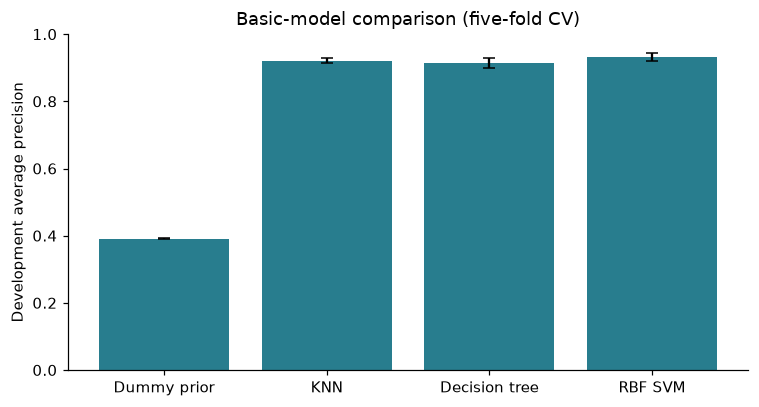

The strongest basic model by development AP is RBF SVM (0.9328).
Its AP gain over the prior baseline is +0.5413.
KNN is sensitive to distances in the encoded feature space; a tree learns explicit splits;
the RBF SVM combines features through a smooth nonlinear boundary. Observed AP differences
measure ranking quality, not the causal usefulness of an advisor intervention.


In [11]:
basic_names = ["KNN", "Decision tree", "RBF SVM"]
basic_results = pd.DataFrame(search_records).set_index("Model")
display(basic_results.round(4))
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(basic_results.index, basic_results["CV AP"], yerr=basic_results["Fold SD"], capsize=4, color="#287D8E")
ax.set(ylabel="Development average precision", ylim=(0, 1), title="Basic-model comparison (five-fold CV)")
plt.tight_layout()
plt.show()

best_basic_name = basic_results.loc[basic_names, "CV AP"].idxmax()
best_basic_ap = basic_results.loc[best_basic_name, "CV AP"]
print(f"The strongest basic model by development AP is {best_basic_name} ({best_basic_ap:.4f}).")
print(f"Its AP gain over the prior baseline is {best_basic_ap - basic_results.loc['Dummy prior', 'CV AP']:+.4f}.")
print("KNN is sensitive to distances in the encoded feature space; a tree learns explicit splits;")
print("the RBF SVM combines features through a smooth nonlinear boundary. Observed AP differences")
print("measure ranking quality, not the causal usefulness of an advisor intervention.")

### 6.2 Operational rule for advisors

We assume advisors can follow up **20% of a cohort**. This is a declared scenario, not an observed institutional capacity. Precision@20% measures how many contacted students are recorded dropout cases; recall@20% measures how many of all dropout cases are reached. We use `ceil(0.20 * n)` and a stable row-order tie break. Ties, especially in the dummy baseline, do not imply meaningful risk differences.

For a separate binary alert rule, each model's threshold is chosen using training out-of-fold predictions to maximize **F2**, which weights recall more heavily than precision. This preference is explicit, not an estimated intervention cost. The threshold rule and fixed-capacity ranking rule answer different operational questions. Neither raw SVM margins nor uncalibrated classifier scores are presented as validated probabilities.

In [12]:
CAPACITY = 0.20
development_scores = {}
chosen_thresholds = {}
development_rows = []

def risk_scores(estimator, X_input):
    if hasattr(estimator, "predict_proba"):
        return estimator.predict_proba(X_input)[:, 1]
    return estimator.decision_function(X_input)

def capacity_metrics(y_true, scores, capacity=CAPACITY):
    labels = np.asarray(y_true)
    order = np.argsort(-np.asarray(scores), kind="stable")
    k = max(1, math.ceil(capacity * len(labels)))
    reached = int(labels[order[:k]].sum())
    return {"Contacted": k, "Dropouts reached": reached,
            "Precision@20%": reached / k, "Recall@20%": reached / labels.sum()}

def register_development(name):
    model = fitted_models[name]
    method = "predict_proba" if hasattr(model, "predict_proba") else "decision_function"
    with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        oof = cross_val_predict(clone(model), X_train, y_train, cv=cv, method=method, n_jobs=1)
    scores = oof[:, 1] if method == "predict_proba" else oof
    precision, recall, thresholds = precision_recall_curve(y_train, scores)
    f2 = np.divide(5 * precision[:-1] * recall[:-1], 4 * precision[:-1] + recall[:-1],
                   out=np.zeros(len(thresholds)), where=(4 * precision[:-1] + recall[:-1]) != 0)
    threshold = float(thresholds[np.argmax(f2)])
    chosen_thresholds[name] = threshold
    development_scores[name] = scores
    predictions = scores >= threshold
    row = {"Model": name, "OOF AP (development)": average_precision_score(y_train, scores),
           "Threshold": threshold, "F2 at threshold": fbeta_score(y_train, predictions, beta=2),
           **capacity_metrics(y_train, scores)}
    development_rows.append(row)
    n_warn = sum(issubclass(w.category, ConvergenceWarning) for w in caught)
    print(f"{name}: threshold={threshold:.4f}, development F2={row['F2 at threshold']:.4f}; convergence warnings={n_warn}")

for name in ["Dummy prior"] + basic_names:
    register_development(name)
display(pd.DataFrame(development_rows).set_index("Model").round(4))
print("These thresholds are now fixed. OOF estimates after parameter tuning remain development estimates.")

Dummy prior: threshold=0.3913, development F2=0.7629; convergence warnings=0


KNN: threshold=0.1626, development F2=0.8539; convergence warnings=0


Decision tree: threshold=0.2069, development F2=0.8599; convergence warnings=0


RBF SVM: threshold=-0.9074, development F2=0.8699; convergence warnings=0


,OOF AP (development),Threshold,F2 at threshold,Contacted,Dropouts reached,Precision@20%,Recall@20%
Model,,,,,,,
Dummy prior,0.3911,0.3913,0.7629,581,231,0.3976,0.2032
KNN,0.9204,0.1626,0.8539,581,580,0.9983,0.5101
Decision tree,0.9176,0.2069,0.8599,581,572,0.9845,0.5031
RBF SVM,0.9328,-0.9074,0.8699,581,581,1.0000,0.5110


These thresholds are now fixed. OOF estimates after parameter tuning remain development estimates.


## 7. Implement boosting and bagging and explain all steps

### 7.1 Bagging: bootstrap-aggregated decision trees

For each fitted ensemble, bagging draws bootstrap samples from the training fold, fits a separate decision tree to each sample, and averages the class-probability outputs. Trees are suitable high-variance base learners: averaging can reduce sensitivity to individual training observations. We compare 30 and 60 trees and base-tree depths 5 and unrestricted. Each tree uses a minimum leaf size of 5. This is explicit bagging, not a random forest.

### 7.2 Boosting: AdaBoost with decision stumps

AdaBoost fits weak learners sequentially, reweighting training observations to emphasize errors from earlier rounds. It combines their predictions using learned weights. The base estimator is a depth-1 decision tree (a stump), which is deliberately weaker than the bagging trees. We compare 40/80 stages and learning rates 0.3/1.0 to control the amount of boosting. No resampling is applied before cross-validation.

Thus the ensemble algorithms differ: bootstrap aggregation versus adaptive boosting, with different base-tree complexity. Both preprocess and select features inside the training folds, using 75%/100% retention. The steps are specified explicitly in the constructors and fitted stage counts are inspected below. Ensembles are not guaranteed to outperform a single model.

### 7.3 Gradient boosting with shallow trees

As a second boosting mechanism, `GradientBoostingClassifier` adds shallow trees sequentially to improve log-loss. Unlike AdaBoost's error-driven weighting, it follows the gradient of the classification loss. We compare 60/120 stages and learning rates 0.05/0.1, with depth 2 and minimum leaf size 10. Feature retention is searched over 75/100%. This separates the choice of boosting mechanism from the single AdaBoost implementation, without claiming a controlled comparison of identical weak learners.

Bagging and boosting here use different tree complexity and learning procedures. Bagging uses depth-5 or unrestricted trees, AdaBoost uses stumps, and gradient boosting uses depth-2 trees.

In [13]:
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(min_samples_leaf=5, random_state=RANDOM_STATE),
    bootstrap=True, max_samples=1.0, n_jobs=1, random_state=RANDOM_STATE,
)
boosting = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE,
)
run_search("Bagging trees", make_model_pipeline(bagging), {
    "model__n_estimators": [30, 60], "model__estimator__max_depth": [5, None],
    "selection__percentile": [75, 100],
})
run_search("AdaBoost stumps", make_model_pipeline(boosting), {
    "model__n_estimators": [40, 80], "model__learning_rate": [0.3, 1.0],
    "selection__percentile": [75, 100],
})
for name in ["Bagging trees", "AdaBoost stumps"]:
    ensemble = fitted_models[name].named_steps["model"]
    print(name, "fitted base learners:", len(ensemble.estimators_))
    register_development(name)

run_search("Gradient boosting", make_model_pipeline(GradientBoostingClassifier(
    max_depth=2, min_samples_leaf=10, random_state=RANDOM_STATE)), {
    "model__n_estimators": [60, 120], "model__learning_rate": [0.05, 0.1],
    "selection__percentile": [75, 100],
})
register_development("Gradient boosting")


Bagging trees: CV AP=0.9361, 36.7s; best={'model__estimator__max_depth': 5, 'model__n_estimators': 60, 'selection__percentile': 75}


AdaBoost stumps: CV AP=0.9341, 18.7s; best={'model__learning_rate': 1.0, 'model__n_estimators': 80, 'selection__percentile': 75}
Bagging trees fitted base learners: 60


Bagging trees: threshold=0.1764, development F2=0.8697; convergence warnings=0
AdaBoost stumps fitted base learners: 80


AdaBoost stumps: threshold=0.4350, development F2=0.8682; convergence warnings=0


Gradient boosting: CV AP=0.9395, 18.7s; best={'model__learning_rate': 0.05, 'model__n_estimators': 120, 'selection__percentile': 100}


Gradient boosting: threshold=0.1578, development F2=0.8732; convergence warnings=0


## 8. Compare basic models, ensembles, and cross-course transfer

### 8.1 Common-population development comparison

Base models and ensembles use identical training rows and five stratified folds. Their selected CV scores are development estimates after tuning, not unbiased nested-CV performance estimates. Feature and hyperparameter searches differ in size.

### 8.2 Cross-course weight transfer

Transfer is interpreted as adapting a network trained on other courses to a target course, chosen as the most frequent course **in training data only**. Course codes remain anonymous identifiers. No external data or `Enrolled` records are used.

1. Separate source courses from the target course; split target development data 75/25 into adaptation and validation rows.
2. Fit feature engineering, encoding, scaling, and the 75% feature filter **on source rows only**. Both arms use this fixed representation, so the comparison isolates network initialization conditional on that representation.
3. Pretrain a (64, 32) network on source labels, then copy its weights and fine-tune all layers for exactly 120 epochs on target adaptation rows.
4. Compare a randomly initialized network with the same architecture, regularization, seed and 120 target epochs on the same adaptation rows.
5. Refit both prespecified arms on all target development rows, retaining the same source representation. Evaluate them on the target-course test subset only in section 10.

The transfer arm has additional source training; its cost is reported separately. `warm_start=True` reuses weights while `fit` restarts Adam's optimizer state. High patience ensures both target arms receive the full fixed epoch budget. Reaching the cap is reported as a convergence warning. Validation results do not trigger changes to architecture, epoch counts, or either arm. One course and one seed cannot establish general transfer benefits.

The scratch arm also uses source-fitted preprocessing and selection. This is a weight-initialization comparison, not a comparison against a workflow with no access to source information. Target-course results and full-population results have different evaluation populations and must not be mixed in one ranking.

In [14]:
from copy import deepcopy

development_comparison = pd.DataFrame(search_records).set_index("Model")
display(development_comparison.round(4))
for name in ["Bagging trees", "AdaBoost stumps", "Gradient boosting"]:
    print(f"{name}: CV AP difference vs strongest basic = {development_comparison.loc[name, 'CV AP'] - best_basic_ap:+.4f}")

target_course = X_train["Course"].value_counts().idxmax()
source_X = X_train.loc[X_train["Course"] != target_course]
source_y = y_train.loc[source_X.index]
target_X = X_train.loc[X_train["Course"] == target_course]
target_y = y_train.loc[target_X.index]
adapt_X, transfer_val_X, adapt_y, transfer_val_y = train_test_split(
    target_X, target_y, test_size=0.25, stratify=target_y, random_state=RANDOM_STATE)
assert set(source_X.index).isdisjoint(target_X.index)
assert set(adapt_X.index).isdisjoint(transfer_val_X.index)
assert all(set(labels) == {0, 1} for labels in [source_y, adapt_y, transfer_val_y])

transfer_representation = make_model_pipeline(DummyClassifier(), percentile=75)[:-1]
source_Z = transfer_representation.fit_transform(source_X, source_y)
adapt_Z = transfer_representation.transform(adapt_X)
transfer_val_Z = transfer_representation.transform(transfer_val_X)
target_Z = transfer_representation.transform(target_X)

def transfer_network():
    return MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
        alpha=0.01, learning_rate_init=0.001, batch_size=64, early_stopping=False,
        max_iter=180, n_iter_no_change=15, tol=1e-4, random_state=RANDOM_STATE)

transfer_fit_records = []
def fit_transfer(label, model, data, target):
    start = perf_counter()
    with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(data, target)
    transfer_fit_records.append({"Stage": label, "Seconds": perf_counter() - start,
        "Epochs": model.n_iter_, "Convergence warnings": sum(issubclass(w.category, ConvergenceWarning) for w in caught)})
    return model

source_network = fit_transfer("Source pretraining", transfer_network(), source_Z, source_y)
transfer_validation = deepcopy(source_network).set_params(warm_start=True, max_iter=120, n_iter_no_change=1000)
assert all(np.array_equal(a, b) for a, b in zip(source_network.coefs_, transfer_validation.coefs_))
fit_transfer("Validation fine-tuning", transfer_validation, adapt_Z, adapt_y)
scratch_validation = fit_transfer("Validation scratch", transfer_network().set_params(max_iter=120, n_iter_no_change=1000), adapt_Z, adapt_y)
transfer_validation_rows = []
for name, model in [("Scratch", scratch_validation), ("Source-pretrained", transfer_validation)]:
    scores = model.predict_proba(transfer_val_Z)[:, 1]
    transfer_validation_rows.append({"Arm": name, "Target validation AP": average_precision_score(transfer_val_y, scores),
        **capacity_metrics(transfer_val_y, scores)})
print(f"Target course code: {target_course}; source: {len(source_X)}, target development: {len(target_X)}")
print(f"Target adaptation: {len(adapt_X)}, target validation: {len(transfer_val_X)}")
display(pd.DataFrame(transfer_validation_rows).set_index("Arm").round(4))
print("These validation results are descriptive; both fixed arms proceed to final evaluation.")

transfer_final = deepcopy(source_network).set_params(warm_start=True, max_iter=120, n_iter_no_change=1000)
fit_transfer("Final fine-tuning", transfer_final, target_Z, target_y)
scratch_final = fit_transfer("Final scratch", transfer_network().set_params(max_iter=120, n_iter_no_change=1000), target_Z, target_y)
assert all(model.n_iter_ == 120 for model in [transfer_validation, scratch_validation, transfer_final, scratch_final])
display(pd.DataFrame(transfer_fit_records).set_index("Stage").round(3))


,CV AP,Fold SD,CV ROC-AUC,Search seconds,Refit seconds,Candidates,Convergence warnings
Model,,,,,,,
Dummy prior,0.3915,0.0008,0.5000,0.4562,0.0403,1,0
KNN,0.9211,0.0074,0.9255,4.9196,0.0392,8,0
Decision tree,0.9133,0.0151,0.9249,3.6148,0.0676,8,0
RBF SVM,0.9328,0.0114,0.9355,13.9870,0.2720,8,0
Bagging trees,0.9361,0.0092,0.9412,36.6611,0.9141,8,0
AdaBoost stumps,0.9341,0.0063,0.9388,18.6635,0.4486,8,0
Gradient boosting,0.9395,0.0071,0.9434,18.7194,0.7411,8,0


Bagging trees: CV AP difference vs strongest basic = +0.0032
AdaBoost stumps: CV AP difference vs strongest basic = +0.0013
Gradient boosting: CV AP difference vs strongest basic = +0.0066


Target course code: 12; source: 2369, target development: 535
Target adaptation: 401, target validation: 134


,Target validation AP,Contacted,Dropouts reached,Precision@20%,Recall@20%
Arm,,,,,
Scratch,0.8151,27,17,0.6296,0.7083
Source-pretrained,0.7932,27,17,0.6296,0.7083


These validation results are descriptive; both fixed arms proceed to final evaluation.


,Seconds,Epochs,Convergence warnings
Stage,,,
Source pretraining,2.850,180,1
Validation fine-tuning,0.341,120,1
Validation scratch,0.339,120,1
Final fine-tuning,0.486,120,1
Final scratch,0.452,120,1


## 9. Implement a deep neural network with hyperparameter tuning

### 9.1 Architecture and tuning choices

The inputs are tabular student measurements without an established spatial ordering, so we use a **fully connected deep neural network**, rather than imposing a CNN structure. `MLPClassifier` implements dense hidden layers, nonlinear activations, backpropagation, and a logistic binary output.

To follow the assignment's allowance to use preprocessed inputs directly, this model uses the original 32 retained predictors after encoding, standardization, and constant filtering, with no engineered features or supervised feature selection (percentile=100). This difference from the other models is explicit and limits attributing performance differences solely to algorithm choice.

| Hyperparameter | Values | Justification |
| --- | --- | --- |
| Hidden architecture | (32,16), (64,32,16) | Compares two and three hidden layers, with different capacity on a small dataset. |
| L2 penalty alpha | 0.001, 0.01 | Tests stronger regularization against overfitting. |
| Initial learning rate | 0.0005, 0.001 | Tests two Adam step sizes affecting training speed and stability. |

ReLU activation and Adam are held fixed. Training is capped at 200 epochs, with early stopping on an internal 15% validation subset and patience 15. Scikit-learn's classifier early stopping uses validation accuracy, while outer search uses AP; these objectives need not choose the same stopping point. Internal validation is drawn from the current training fold only. Outer-fold preprocessing can include its internal early-stopping rows, but never the outer validation/test rows.

Eight configurations are evaluated in five folds. The selected configuration is then refitted on the training set. Iteration-limit warnings, training loss, and internal validation accuracy are reported; reaching the maximum does not demonstrate convergence. The fixed seed supports reproduction, but a multi-seed neural-network study remains future work. This CPU implementation has no GPU acceleration.

Deep neural network: CV AP=0.9357, 18.8s; best={'model__alpha': 0.01, 'model__hidden_layer_sizes': (32, 16), 'model__learning_rate_init': 0.0005}


Deep neural network: threshold=0.1651, development F2=0.8723; convergence warnings=0
Best hidden architecture: (32, 16)
Refit epochs: 32 / 200
Hidden layers: 2
Trainable parameters: 7713


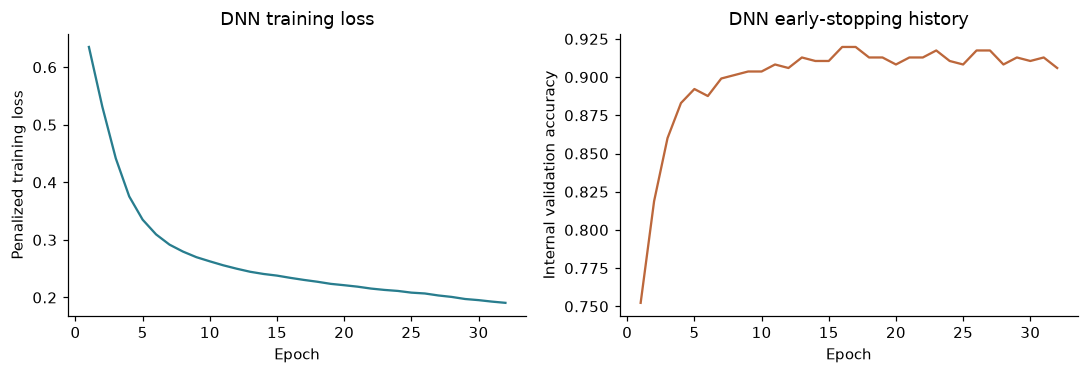

,param_model__hidden_layer_sizes,param_model__alpha,param_model__learning_rate_init,mean_test_AP,std_test_AP,mean_fit_time
4,"(32, 16)",0.010,0.0005,0.9357,0.0053,0.4432
0,"(32, 16)",0.001,0.0005,0.9355,0.0052,0.4463
5,"(32, 16)",0.010,0.0010,0.9342,0.0046,0.3644
1,"(32, 16)",0.001,0.0010,0.9331,0.0049,0.3761
7,"(64, 32, 16)",0.010,0.0010,0.9285,0.0099,0.4364
2,"(64, 32, 16)",0.001,0.0005,0.9259,0.0116,0.4959
6,"(64, 32, 16)",0.010,0.0005,0.9255,0.0114,0.4966
3,"(64, 32, 16)",0.001,0.0010,0.9248,0.0122,0.4576


In [15]:
deep_network = MLPClassifier(
    activation="relu", solver="adam", batch_size=64, max_iter=200,
    early_stopping=True, validation_fraction=0.15, n_iter_no_change=15,
    tol=1e-4, random_state=RANDOM_STATE,
)
run_search("Deep neural network", make_model_pipeline(deep_network, engineered=False, percentile=100), {
    "model__hidden_layer_sizes": [(32, 16), (64, 32, 16)],
    "model__alpha": [0.001, 0.01],
    "model__learning_rate_init": [0.0005, 0.001],
})
register_development("Deep neural network")
nn = fitted_models["Deep neural network"].named_steps["model"]
print("Best hidden architecture:", nn.hidden_layer_sizes)
print("Refit epochs:", nn.n_iter_, "/", nn.max_iter)
print("Hidden layers:", nn.n_layers_ - 2)
print("Trainable parameters:", sum(w.size for w in nn.coefs_) + sum(b.size for b in nn.intercepts_))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(np.arange(1, len(nn.loss_curve_) + 1), nn.loss_curve_, color="#287D8E")
axes[0].set(xlabel="Epoch", ylabel="Penalized training loss", title="DNN training loss")
axes[1].plot(np.arange(1, len(nn.validation_scores_) + 1), nn.validation_scores_, color="#BC673B")
axes[1].set(xlabel="Epoch", ylabel="Internal validation accuracy", title="DNN early-stopping history")
plt.tight_layout()
plt.show()

nn_trials = pd.DataFrame(searches["Deep neural network"].cv_results_)
display(nn_trials[["param_model__hidden_layer_sizes", "param_model__alpha",
                   "param_model__learning_rate_init", "mean_test_AP", "std_test_AP",
                   "mean_fit_time"]].sort_values("mean_test_AP", ascending=False).round(4))

## 10. Compare complexity, computation time, and classification performance

### 10.1 Freeze model choices before final evaluation

The primary recommended model is selected by the highest development CV AP among non-dummy candidates. The final comparison evaluates every already-fixed model once on the same test set. Test results describe these fitted candidates; they are not used to retune parameters, thresholds, capacity, or model choice. No test-guided changes are made after this point.

We report AP, ROC-AUC, accuracy, balanced accuracy, precision, recall, F1, F2, a confusion matrix, and fixed-capacity precision/recall. Binary predictions use each model's training-OOF F2 threshold. If an SVM score scale changes after refitting, the transferred threshold may behave differently; capacity-based ranking does not depend on that threshold.

Training-search time measures the complete search including its final refit; refit time measures a single selected fit including preprocessing. Prediction time is the median of five full-test scoring passes after one warm-up, divided by the number of rows. It is a local batch CPU measurement, not a deployment latency guarantee. Model complexity is reported as concrete counts, not directly comparable units across all algorithms.

### Development-only calibration of the selected workflow

Before opening the test set, we lock the full-population recommendation by CV AP and fit a **separate sigmoid-calibrated variant**. Five stratified calibration folds each refit a clone of the complete chosen pipeline on that fold's training rows; calibration uses predictions for its held-out rows. `ensemble=True` averages the calibrated fold models at prediction time.

This fits no calibrator on test outcomes. Hyperparameters were already selected using the same development data, so internal calibration scores would not be an independent evaluation. Calibration can alter ranking and uses an ensemble of fold fits; it is an additional workflow, not a replacement chosen after seeing test results. Primary test tables and F2 thresholds continue to describe the original selected models. Section 10.5 evaluates the calibrated variant without selecting a method on test performance.

In [16]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss, log_loss

pretest_table = pd.DataFrame(search_records).set_index("Model")
locked_name = pretest_table.drop(index="Dummy prior")["CV AP"].idxmax()
calibrated_selected = CalibratedClassifierCV(
    estimator=clone(fitted_models[locked_name]), method="sigmoid", cv=cv, ensemble=True, n_jobs=1)
calibration_begin = perf_counter()
with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as calibration_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    calibrated_selected.fit(X_train, y_train)
calibration_seconds = perf_counter() - calibration_begin
print("Pre-test selected workflow:", locked_name)
print(f"Calibration workflow fit time: {calibration_seconds:.3f}s")
print("Calibration convergence warnings:", sum(issubclass(w.category, ConvergenceWarning) for w in calibration_warnings))

Pre-test selected workflow: Gradient boosting
Calibration workflow fit time: 3.127s
Calibration convergence warnings: 0


In [17]:
final_development_table = pd.DataFrame(search_records).set_index("Model")
non_dummy = final_development_table.drop(index="Dummy prior")
recommended_name = non_dummy["CV AP"].idxmax()
print("Recommendation frozen using development CV:", recommended_name)
print("Fixed support capacity:", CAPACITY)
print("All thresholds were fixed from training out-of-fold scores before test evaluation.")

test_scores = {}
test_predictions = {}
final_rows = []

def complexity_description(pipeline):
    model = pipeline.named_steps["model"]
    if isinstance(model, KNeighborsClassifier):
        return f"{len(model._fit_X)} stored training vectors; k={model.n_neighbors}"
    if isinstance(model, DecisionTreeClassifier):
        return f"{model.tree_.node_count} nodes; depth={model.get_depth()}"
    if isinstance(model, SVC):
        return f"{int(model.n_support_.sum())} support vectors"
    if isinstance(model, GradientBoostingClassifier):
        return f"{model.n_estimators_} stages; {sum(e.tree_.node_count for e in model.estimators_.ravel())} total nodes"
    if isinstance(model, (BaggingClassifier, AdaBoostClassifier)):
        return f"{len(model.estimators_)} trees; {sum(e.tree_.node_count for e in model.estimators_)} total nodes"
    if isinstance(model, MLPClassifier):
        return f"{sum(w.size for w in model.coefs_) + sum(b.size for b in model.intercepts_)} parameters"
    return "Class-prior constant"

for name, model in fitted_models.items():
    with threadpool_limits(limits=1):
        scores = risk_scores(model, X_test)
        timings = []
        for _ in range(5):
            begin = perf_counter()
            risk_scores(model, X_test)
            timings.append(perf_counter() - begin)
    assert np.isfinite(scores).all()
    predicted = scores >= chosen_thresholds[name]
    test_scores[name] = scores
    test_predictions[name] = predicted
    transformed_dim = model.named_steps["selection"].get_support().sum()
    final_rows.append({
        "Model": name, "Test AP": average_precision_score(y_test, scores),
        "ROC-AUC": roc_auc_score(y_test, scores), "Accuracy": accuracy_score(y_test, predicted),
        "Balanced accuracy": balanced_accuracy_score(y_test, predicted),
        "Precision": precision_score(y_test, predicted, zero_division=0),
        "Recall": recall_score(y_test, predicted), "F1": f1_score(y_test, predicted),
        "F2": fbeta_score(y_test, predicted, beta=2), **capacity_metrics(y_test, scores),
        "Input dimensions": int(transformed_dim),
        "Search seconds": final_development_table.loc[name, "Search seconds"],
        "Refit seconds": final_development_table.loc[name, "Refit seconds"],
        "Score ms/student": 1000 * np.median(timings) / len(X_test),
        "Complexity": complexity_description(model),
    })

final_results = pd.DataFrame(final_rows).set_index("Model")
display(final_results[["Test AP", "ROC-AUC", "Accuracy", "Balanced accuracy", "Precision",
                       "Recall", "F1", "F2", "Precision@20%", "Recall@20%"]].round(4))
display(final_results[["Input dimensions", "Search seconds", "Refit seconds", "Score ms/student", "Complexity"]].round(4))

Recommendation frozen using development CV: Gradient boosting
Fixed support capacity: 0.2
All thresholds were fixed from training out-of-fold scores before test evaluation.


,Test AP,ROC-AUC,Accuracy,Balanced accuracy,Precision,Recall,F1,F2,Precision@20%,Recall@20%
Model,,,,,,,,,,
Dummy prior,0.3912,0.5000,0.3912,0.5000,0.3912,1.0000,0.5624,0.7626,0.3973,0.2042
KNN,0.9483,0.9515,0.8099,0.8332,0.6881,0.9401,0.7946,0.8760,1.0000,0.5141
Decision tree,0.9439,0.9524,0.8237,0.8458,0.7042,0.9472,0.8078,0.8860,0.9932,0.5106
RBF SVM,0.9617,0.9687,0.8223,0.8490,0.6952,0.9718,0.8106,0.9002,1.0000,0.5141
Bagging trees,0.9592,0.9614,0.8416,0.8605,0.7290,0.9472,0.8239,0.8937,1.0000,0.5141
AdaBoost stumps,0.9605,0.9641,0.8540,0.8719,0.7445,0.9542,0.8364,0.9033,1.0000,0.5141
Gradient boosting,0.9617,0.9657,0.8402,0.8606,0.7246,0.9542,0.8237,0.8974,1.0000,0.5141
Deep neural network,0.9600,0.9677,0.8223,0.8497,0.6942,0.9754,0.8111,0.9023,1.0000,0.5141


,Input dimensions,Search seconds,Refit seconds,Score ms/student,Complexity
Model,,,,,
Dummy prior,175,0.4562,0.0403,0.0117,Class-prior constant
KNN,175,4.9196,0.0392,0.0440,2904 stored training vectors; k=31
Decision tree,234,3.6148,0.0676,0.0115,85 nodes; depth=8
RBF SVM,175,13.9870,0.2720,0.0944,875 support vectors
Bagging trees,175,36.6611,0.9141,0.0289,60 trees; 3080 total nodes
AdaBoost stumps,175,18.6635,0.4486,0.0326,80 trees; 240 total nodes
Gradient boosting,234,18.7194,0.7411,0.0129,120 stages; 818 total nodes
Deep neural network,223,18.8374,0.4756,0.0089,7713 parameters


### Computational complexity

Let n be the training size, d the encoded/selected input dimension, B the number of base learners, h tree depth, s the support-vector count, P the network parameter count, and E the number of training epochs. These are explanatory approximations, excluding preprocessing and hyperparameter-search repetitions.

| Model | Training or storage cost | Approximate scoring cost per student |
| --- | --- | --- |
| KNN | Stores O(n d) values; fitting is relatively cheap | Brute-force distances O(n d), plus neighbour selection |
| Decision tree | Split search depends on n, d, and implementation; typically grows with depth and candidate splits | O(h) traversed nodes |
| RBF SVM | Kernel construction can involve O(n squared d); optimization depends on the data and solver | O(s d) kernel evaluations |
| Bagging trees | B tree fits; independent fits could be parallelized, but are serial here | O(B h), using average tree depth |
| AdaBoost stumps | B sequential weak-learner fits and weight updates | O(B) stump predictions |
| Deep network | Approximately O(E n P) floating-point work | O(P) dense-layer work |
| Gradient boosting | Sequential shallow-tree fits across B stages | O(B h) tree traversal |
| Cross-course transfer | Source pretraining plus target adaptation | O(P) network work after source-fitted preprocessing |

The measured times and fitted counts in section 10.1 show the actual scale of this experiment. Counts across different model families are not interchangeable measures of interpretability or memory. Transfer costs are reported by stage in section 8. Both transfer arms have the same network architecture at inference, but the pretrained arm also pays for source training.


### 10.2 Curves, confusion matrices, and advisor-capacity trade-offs

The precision-recall curves compare positive-class ranking. ROC curves provide a complementary view of true-positive versus false-positive rates. Confusion matrices use the development-selected thresholds. The capacity curve asks how many recorded dropout cases would be reached as the follow-up budget changes; the 20% operating point remains fixed regardless of this descriptive test plot.

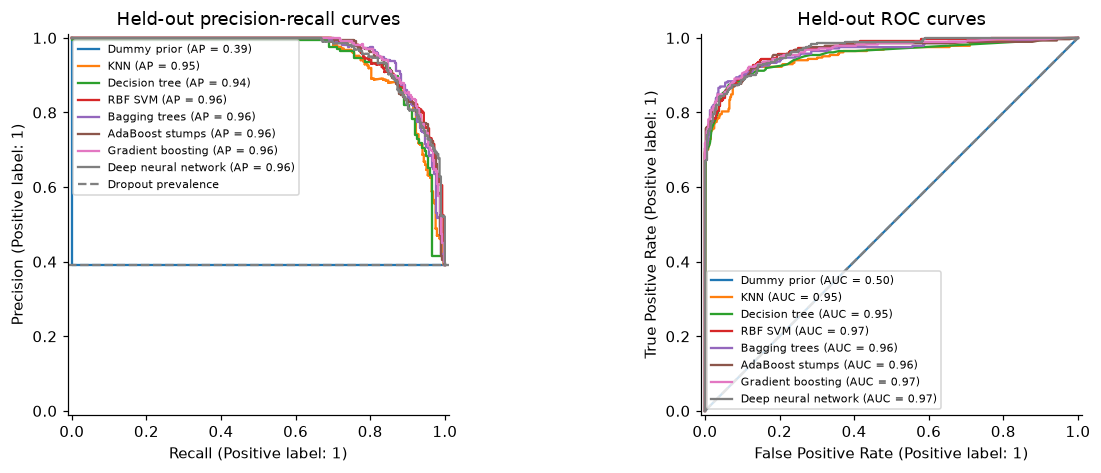

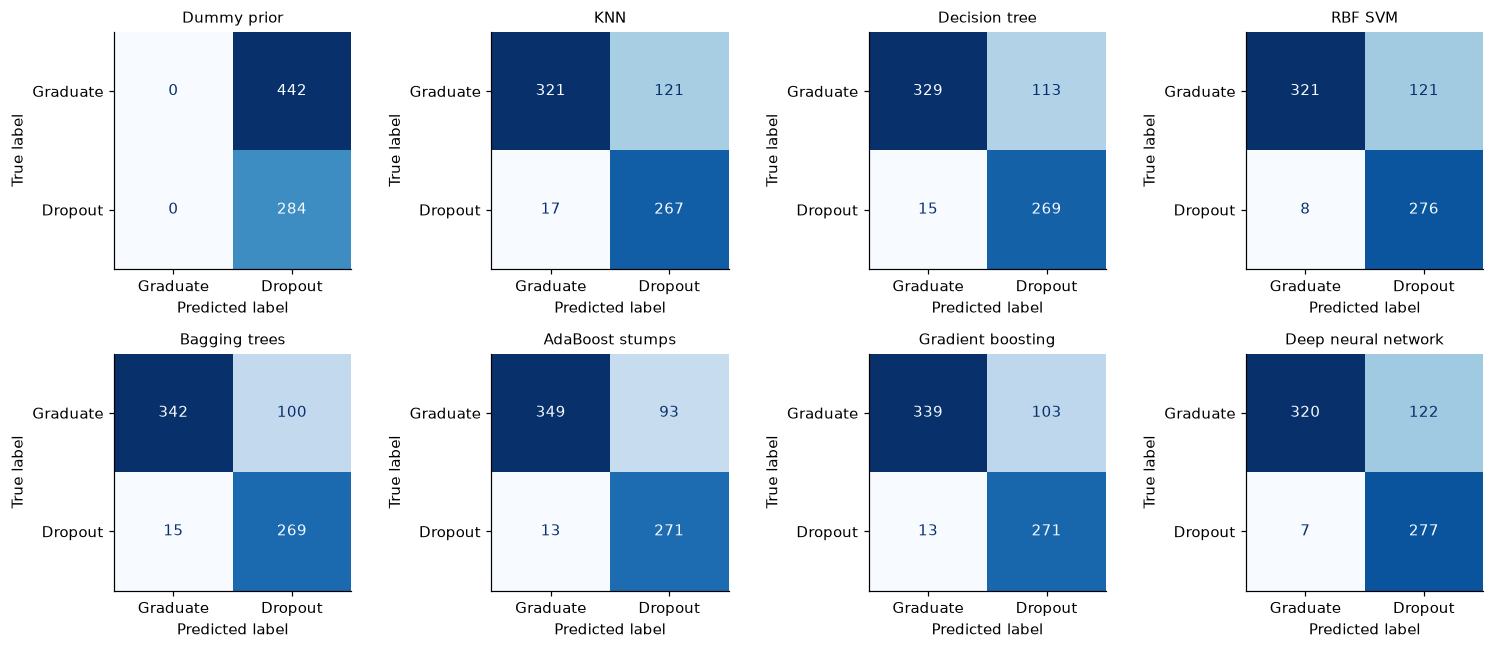

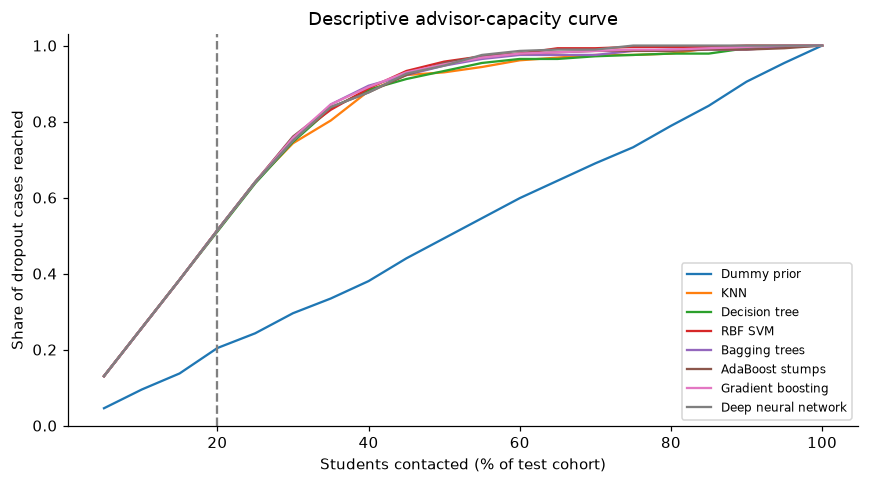

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for name, scores in test_scores.items():
    PrecisionRecallDisplay.from_predictions(y_test, scores, name=name, ax=axes[0])
    RocCurveDisplay.from_predictions(y_test, scores, name=name, ax=axes[1])
axes[0].axhline(y_test.mean(), linestyle="--", color="grey", label="Dropout prevalence")
axes[0].set_title("Held-out precision-recall curves")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey")
axes[1].set_title("Held-out ROC curves")
for ax in axes:
    ax.legend(fontsize=7, loc="best")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, (name, predicted) in zip(axes.flat, test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, predicted, display_labels=["Graduate", "Dropout"],
                                           ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name, fontsize=10)
for ax in list(axes.flat)[len(test_predictions):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
capacities = np.linspace(0.05, 1, 20)
for name, scores in test_scores.items():
    recalls = [capacity_metrics(y_test, scores, c)["Recall@20%"] for c in capacities]
    ax.plot(capacities * 100, recalls, label=name)
ax.axvline(20, linestyle="--", color="grey")
ax.set(xlabel="Students contacted (% of test cohort)", ylabel="Share of dropout cases reached",
       title="Descriptive advisor-capacity curve", ylim=(0, 1.03))
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 10.3 Uncertainty and explanation

We estimate uncertainty for the development-selected model with 1,000 stratified bootstrap resamples of the test predictions. The intervals hold the fitted model fixed and do not capture variability from retraining, hyperparameter selection, institutional change, or incomplete outcome follow-up. For capacity metrics, each resample is reranked; ties follow the sampled row order.

Permutation importance is computed on the **training set** for the selected model, permuting raw input columns and scoring AP through the complete pipeline. Engineered features are recomputed after each permutation. This describes model dependence on an input, not a causal effect; correlated semester variables can share or mask importance. It is not used to revise the selected features or the final test evaluation.

Conditional 95% bootstrap intervals for Gradient boosting


,2.5%,97.5%
AP,0.9482,0.9744
Precision@20%,1.0000,1.0000
Recall@20%,0.5141,0.5141


,Raw feature,Training AP decrease,Repeat SD
26,Curricular units 2nd sem (approved),0.3386,0.0152
20,Curricular units 1st sem (approved),0.0752,0.0039
24,Curricular units 2nd sem (enrolled),0.0347,0.0010
18,Curricular units 1st sem (enrolled),0.0217,0.0012
27,Curricular units 2nd sem (grade),0.0059,0.0006
3,Course,0.0052,0.0005
14,Scholarship holder,0.0044,0.0003
15,Age at enrollment,0.0032,0.0005
21,Curricular units 1st sem (grade),0.0011,0.0002
1,Application mode,0.0004,0.0001


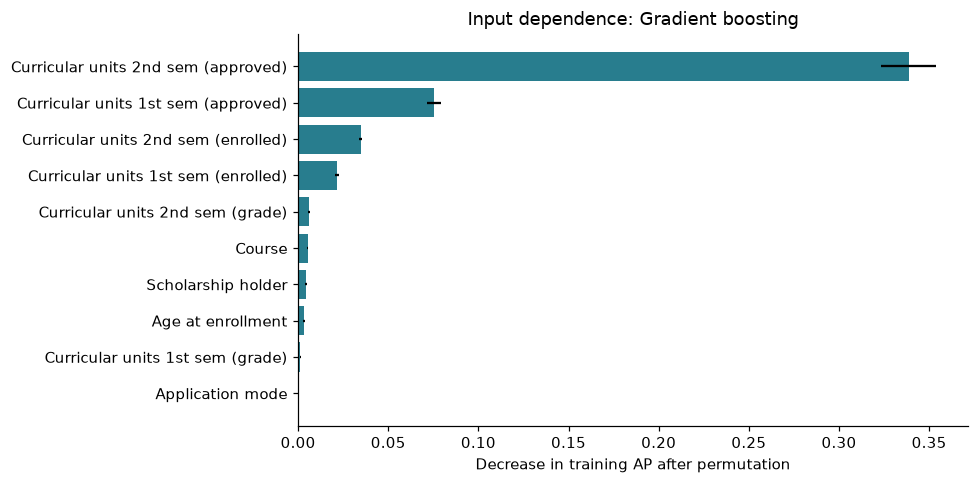

In [19]:
rng = np.random.default_rng(RANDOM_STATE)
labels = y_test.to_numpy()
positive_indices = np.flatnonzero(labels == 1)
negative_indices = np.flatnonzero(labels == 0)
bootstrap_rows = []
for _ in range(1000):
    sample = np.concatenate([rng.choice(positive_indices, len(positive_indices), replace=True),
                             rng.choice(negative_indices, len(negative_indices), replace=True)])
    rng.shuffle(sample)
    sampled_scores = test_scores[recommended_name][sample]
    bootstrap_rows.append({"AP": average_precision_score(labels[sample], sampled_scores),
                           **capacity_metrics(labels[sample], sampled_scores)})
intervals = pd.DataFrame(bootstrap_rows)[["AP", "Precision@20%", "Recall@20%"]].quantile([0.025, 0.975]).T
intervals.columns = ["2.5%", "97.5%"]
print("Conditional 95% bootstrap intervals for", recommended_name)
display(intervals.round(4))

from sklearn.inspection import permutation_importance
with threadpool_limits(limits=1):
    importance = permutation_importance(fitted_models[recommended_name], X_train, y_train,
                                        scoring="average_precision", n_repeats=5,
                                        random_state=RANDOM_STATE, n_jobs=1)
importance_table = pd.DataFrame({"Raw feature": X_train.columns,
                                "Training AP decrease": importance.importances_mean,
                                "Repeat SD": importance.importances_std}).sort_values("Training AP decrease", ascending=False)
display(importance_table.head(10).round(4))
top = importance_table.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top["Raw feature"], top["Training AP decrease"], xerr=top["Repeat SD"], color="#287D8E")
ax.set(xlabel="Decrease in training AP after permutation", title=f"Input dependence: {recommended_name}")
plt.tight_layout()
plt.show()

### 10.4 Results-based discussion

The following discussion is calculated from the executed results. It distinguishes the model chosen before test evaluation from the descriptive test leader, and connects accuracy, time, and complexity to the advisor scenario.

In [20]:
from IPython.display import Markdown
selected = final_results.loc[recommended_name]
test_leader = final_results.drop(index="Dummy prior")["Test AP"].idxmax()
fastest = final_results.drop(index="Dummy prior")["Refit seconds"].idxmin()
best_capacity = final_results.drop(index="Dummy prior")["Recall@20%"].idxmax()
cm = confusion_matrix(y_test, test_predictions[recommended_name], labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
lift = selected["Precision@20%"] / y_test.mean()
discussion = f"""
**Selected model and prediction performance.** The model selected by training CV is **{recommended_name}**.
On {len(y_test)} held-out students ({int(y_test.sum())} recorded dropout cases), it achieves
AP **{selected['Test AP']:.3f}** and ROC-AUC **{selected['ROC-AUC']:.3f}**.
The descriptive test AP leader is **{test_leader}**. We keep the pre-test recommendation rather than
switching models after observing the test results. The selected model's AP bootstrap interval is
[{intervals.loc['AP', '2.5%']:.3f}, {intervals.loc['AP', '97.5%']:.3f}], conditional on this fitted model.

**Advisor prioritization.** Under the assumed 20% capacity, the selected ranking contacts
**{int(selected['Contacted'])} students** and reaches **{int(selected['Dropouts reached'])}** recorded dropout cases.
Precision among contacted students is **{selected['Precision@20%']:.1%}**, and recall is
**{selected['Recall@20%']:.1%}**. Its precision is **{lift:.2f} times** the test dropout prevalence.
The descriptive fixed-capacity recall leader is {best_capacity}; AP and top-of-list recall can favor
different models because AP summarizes performance across many thresholds.

**Binary alert trade-off.** At the training-selected F2 threshold, the selected model identifies
{tp} dropout cases, misses {fn}, and flags {fp} graduates; {tn} graduates are correctly unflagged.
These alerts may exceed the 20% follow-up capacity. For limited appointments, the ranking policy is
therefore the more directly applicable scenario. False alerts consume advisor time, while missed cases
represent students who would not receive this prioritized support. Neither error count measures the
benefit an actual intervention would produce.

**Computation and complexity.** The selected model's full hyperparameter search took
{selected['Search seconds']:.2f} seconds, its final training refit took {selected['Refit seconds']:.3f} seconds,
and median batch scoring cost was {selected['Score ms/student']:.4f} ms per student on this machine.
Its fitted complexity is: {selected['Complexity']}.
The fastest non-dummy refit was {fastest}. Search times include different candidate counts and objectives,
so they measure this experiment's cost, not an algorithm's universal speed. KNN stores training vectors;
tree and ensemble costs depend on nodes and paths; kernel SVM prediction depends on support vectors;
neural prediction depends on layer dimensions. More computation is justified only when its practical
ranking benefit warrants the cost and maintenance effort.
"""
display(Markdown(discussion))

family_rows = []
for name in ["Bagging trees", "AdaBoost stumps", "Gradient boosting", "Deep neural network"]:
    family_rows.append({"Model": name,
                       "Development AP difference vs best basic": final_development_table.loc[name, "CV AP"] - best_basic_ap,
                       "Test AP": final_results.loc[name, "Test AP"],
                       "Test recall@20%": final_results.loc[name, "Recall@20%"],
                       "Refit seconds": final_results.loc[name, "Refit seconds"]})
display(pd.DataFrame(family_rows).set_index("Model").round(4))
display(Markdown(f"""
**What the model families show.** The table above quantifies whether bagging, boosting, gradient boosting, and the deep network improve on the strongest basic model in development AP. Bagging averages
trees to reduce instability; AdaBoost combines weak stumps sequentially. Gradient boosting follows classification-loss gradients with shallow trees. Cross-course transfer
is evaluated separately on identical target-course test rows.
The supervised deep network directly optimizes classification but has many fitted parameters relative
to this sample size. Differences in preprocessing, architecture, and search budgets prevent attributing
all differences to one isolated algorithmic mechanism.

**Interpretation.** The highest training permutation dependence is on
`{importance_table.iloc[0]['Raw feature']}`. This indicates how this fitted model uses supplied information;
it does not establish a cause of dropout or an effective intervention. Removing correlated inputs may
produce a smaller importance decrease even when they carry relevant information.
"""))


**Selected model and prediction performance.** The model selected by training CV is **Gradient boosting**.
On 726 held-out students (284 recorded dropout cases), it achieves
AP **0.962** and ROC-AUC **0.966**.
The descriptive test AP leader is **RBF SVM**. We keep the pre-test recommendation rather than
switching models after observing the test results. The selected model's AP bootstrap interval is
[0.948, 0.974], conditional on this fitted model.

**Advisor prioritization.** Under the assumed 20% capacity, the selected ranking contacts
**146 students** and reaches **146** recorded dropout cases.
Precision among contacted students is **100.0%**, and recall is
**51.4%**. Its precision is **2.56 times** the test dropout prevalence.
The descriptive fixed-capacity recall leader is KNN; AP and top-of-list recall can favor
different models because AP summarizes performance across many thresholds.

**Binary alert trade-off.** At the training-selected F2 threshold, the selected model identifies
271 dropout cases, misses 13, and flags 103 graduates; 339 graduates are correctly unflagged.
These alerts may exceed the 20% follow-up capacity. For limited appointments, the ranking policy is
therefore the more directly applicable scenario. False alerts consume advisor time, while missed cases
represent students who would not receive this prioritized support. Neither error count measures the
benefit an actual intervention would produce.

**Computation and complexity.** The selected model's full hyperparameter search took
18.72 seconds, its final training refit took 0.741 seconds,
and median batch scoring cost was 0.0129 ms per student on this machine.
Its fitted complexity is: 120 stages; 818 total nodes.
The fastest non-dummy refit was KNN. Search times include different candidate counts and objectives,
so they measure this experiment's cost, not an algorithm's universal speed. KNN stores training vectors;
tree and ensemble costs depend on nodes and paths; kernel SVM prediction depends on support vectors;
neural prediction depends on layer dimensions. More computation is justified only when its practical
ranking benefit warrants the cost and maintenance effort.


,Development AP difference vs best basic,Test AP,Test recall@20%,Refit seconds
Model,,,,
Bagging trees,0.0032,0.9592,0.5141,0.9141
AdaBoost stumps,0.0013,0.9605,0.5141,0.4486
Gradient boosting,0.0066,0.9617,0.5141,0.7411
Deep neural network,0.0028,0.9600,0.5141,0.4756



**What the model families show.** The table above quantifies whether bagging, boosting, gradient boosting, and the deep network improve on the strongest basic model in development AP. Bagging averages
trees to reduce instability; AdaBoost combines weak stumps sequentially. Gradient boosting follows classification-loss gradients with shallow trees. Cross-course transfer
is evaluated separately on identical target-course test rows.
The supervised deep network directly optimizes classification but has many fitted parameters relative
to this sample size. Differences in preprocessing, architecture, and search budgets prevent attributing
all differences to one isolated algorithmic mechanism.

**Interpretation.** The highest training permutation dependence is on
`Curricular units 2nd sem (approved)`. This indicates how this fitted model uses supplied information;
it does not establish a cause of dropout or an effective intervention. Removing correlated inputs may
produce a smaller importance decrease even when they carry relevant information.


In [21]:
best_capacity_value = final_results.drop(index="Dummy prior")["Recall@20%"].max()
capacity_leaders = final_results.drop(index="Dummy prior").index[
    np.isclose(final_results.drop(index="Dummy prior")["Recall@20%"], best_capacity_value)].tolist()
display(Markdown(f"**Fixed-capacity interpretation.** The highest test recall at 20% is {best_capacity_value:.1%}, "
    f"shared by: {', '.join(capacity_leaders)}. Tied models are reported together. "
    "This operating point can fail to separate models even when their overall AP differs. "
    "High performance must also be interpreted alongside unresolved dropout timing."))

**Fixed-capacity interpretation.** The highest test recall at 20% is 51.4%, shared by: KNN, RBF SVM, Bagging trees, AdaBoost stumps, Gradient boosting, Deep neural network. Tied models are reported together. This operating point can fail to separate models even when their overall AP differs. High performance must also be interpreted alongside unresolved dropout timing.

### 10.5 Transfer and probability reliability on held-out data

**Transfer:** compare both fixed arms and all full-population models on the **same target-course test students**. Full-population models also trained on target rows, so their comparison with the transfer arms is a practical workflow comparison with different data access and optimization. The controlled initialization comparison is pretrained versus scratch. Report a paired stratified bootstrap interval for their AP difference, holding both fitted models fixed; it excludes training/seed variability.

**Calibration:** lower Brier score and binary log-loss mean better probability predictions on this test set. AP measures ranking. SVM margins have no probability interpretation and are excluded from raw-probability metrics. We show the predeclared calibrated variant alongside the original workflow only when the latter supplies probabilities. The prior probability is a reference. Reliability curves use five equal-count bins; no recalibration or model revision follows these diagnostics.

Target-course test students: 131; dropouts: 22


,Target test AP,Contacted,Dropouts reached,Precision@20%,Recall@20%
Model,,,,,
Target scratch,0.8844,27,19,0.7037,0.8636
Source pretrained + target fine-tuning,0.9029,27,19,0.7037,0.8636
Dummy prior,0.1679,27,2,0.0741,0.0909
KNN,0.8435,27,17,0.6296,0.7727
Decision tree,0.8451,27,18,0.6667,0.8182
RBF SVM,0.8896,27,18,0.6667,0.8182
Bagging trees,0.8825,27,18,0.6667,0.8182
AdaBoost stumps,0.8837,27,19,0.7037,0.8636
Gradient boosting,0.8828,27,19,0.7037,0.8636


Transfer minus scratch test AP: +0.0185; conditional paired 95% interval: [-0.0614  0.0908]


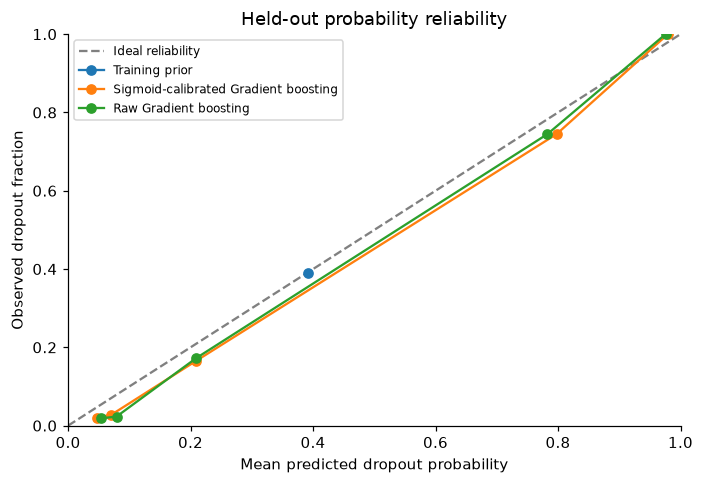

,Brier,Log-loss,AP
Variant,,,
Training prior,0.2382,0.6693,0.3912
Sigmoid-calibrated Gradient boosting,0.0654,0.2251,0.9615
Raw Gradient boosting,0.0651,0.2269,0.9617


Calibration is an additional predeclared workflow; no test-based replacement of the recommendation is made.


In [22]:
assert recommended_name == locked_name
target_test_X = X_test.loc[X_test["Course"] == target_course]
target_test_y = y_test.loc[target_test_X.index]
assert set(target_test_y) == {0, 1}
target_test_Z = transfer_representation.transform(target_test_X)
transfer_test_scores = {
    "Target scratch": scratch_final.predict_proba(target_test_Z)[:, 1],
    "Source pretrained + target fine-tuning": transfer_final.predict_proba(target_test_Z)[:, 1],
}
target_comparison_rows = []
for name, scores in transfer_test_scores.items():
    target_comparison_rows.append({"Model": name, "Target test AP": average_precision_score(target_test_y, scores),
        **capacity_metrics(target_test_y, scores)})
target_mask = (X_test["Course"] == target_course).to_numpy()
for name, scores in test_scores.items():
    target_comparison_rows.append({"Model": name, "Target test AP": average_precision_score(target_test_y, scores[target_mask]),
        **capacity_metrics(target_test_y, scores[target_mask])})
print(f"Target-course test students: {len(target_test_y)}; dropouts: {target_test_y.sum()}")
target_test_results = pd.DataFrame(target_comparison_rows).set_index("Model")
display(target_test_results.round(4))

transfer_rng = np.random.default_rng(RANDOM_STATE)
target_labels = target_test_y.to_numpy()
target_groups = [np.flatnonzero(target_labels == label) for label in [0, 1]]
transfer_deltas = []
for _ in range(1000):
    indices = np.concatenate([transfer_rng.choice(group, len(group), replace=True) for group in target_groups])
    transfer_deltas.append(average_precision_score(target_labels[indices], transfer_test_scores["Source pretrained + target fine-tuning"][indices])
        - average_precision_score(target_labels[indices], transfer_test_scores["Target scratch"][indices]))
delta = target_test_results.loc["Source pretrained + target fine-tuning", "Target test AP"] - target_test_results.loc["Target scratch", "Target test AP"]
print(f"Transfer minus scratch test AP: {delta:+.4f}; conditional paired 95% interval: {np.quantile(transfer_deltas, [0.025, 0.975]).round(4)}")

with threadpool_limits(limits=1):
    calibrated_probabilities = calibrated_selected.predict_proba(X_test)[:, 1]
probability_variants = {
    "Training prior": np.full(len(y_test), y_train.mean()),
    f"Sigmoid-calibrated {recommended_name}": calibrated_probabilities,
}
if hasattr(fitted_models[recommended_name], "predict_proba"):
    probability_variants[f"Raw {recommended_name}"] = test_scores[recommended_name]
probability_rows = []
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Ideal reliability")
for name, probabilities in probability_variants.items():
    assert np.isfinite(probabilities).all() and ((probabilities >= 0) & (probabilities <= 1)).all()
    probability_rows.append({"Variant": name, "Brier": brier_score_loss(y_test, probabilities),
        "Log-loss": log_loss(y_test, probabilities), "AP": average_precision_score(y_test, probabilities)})
    observed, predicted = calibration_curve(y_test, probabilities, n_bins=5, strategy="quantile")
    ax.plot(predicted, observed, marker="o", label=name)
ax.set(xlabel="Mean predicted dropout probability", ylabel="Observed dropout fraction",
       title="Held-out probability reliability", xlim=(0, 1), ylim=(0, 1))
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
display(pd.DataFrame(probability_rows).set_index("Variant").round(4))
print("Calibration is an additional predeclared workflow; no test-based replacement of the recommendation is made.")

### 10.6 Limited subgroup diagnostic

We report the fixed original recommended model by recorded `Gender` code. Local code meanings are unverified, so no demographic names are inferred. The **same global F2 threshold and global top-20% contact list** apply to every group. Precision and recall at the alert threshold, selection rate, and the fraction of group dropout cases reached by the global contact list describe different aspects of the workflow. Small samples and the resolved-outcome restriction limit interpretation. This diagnostic does not establish fairness and does not set group-specific thresholds.

In [23]:
global_contact = np.zeros(len(y_test), dtype=bool)
global_contact[np.argsort(-test_scores[recommended_name], kind="stable")[:math.ceil(CAPACITY * len(y_test))]] = True
subgroup_rows = []
for code in sorted(X_test["Gender"].unique()):
    mask = (X_test["Gender"].to_numpy() == code)
    labels = y_test.to_numpy()[mask]
    alerts = test_predictions[recommended_name][mask]
    contacts = global_contact[mask]
    subgroup_rows.append({"Gender code": code, "Students": int(mask.sum()), "Dropouts": int(labels.sum()),
        "Dropout prevalence": labels.mean(), "Alert precision": precision_score(labels, alerts, zero_division=0),
        "Alert recall": recall_score(labels, alerts, zero_division=0),
        "False-positive rate": float(alerts[labels == 0].mean()) if (labels == 0).any() else np.nan,
        "Global contact selection rate": contacts.mean(),
        "Group dropout recall in global contacts": labels[contacts].sum() / labels.sum() if labels.sum() else np.nan})
display(pd.DataFrame(subgroup_rows).set_index("Gender code").round(4))
print("Differences are descriptive; no group-specific model or threshold is fitted.")

,Students,Dropouts,Dropout prevalence,Alert precision,Alert recall,False-positive rate,Global contact selection rate,Group dropout recall in global contacts
Gender code,,,,,,,,
0,438,130,0.2968,0.6851,0.9538,0.1851,0.1438,0.4846
1,288,154,0.5347,0.7617,0.9545,0.3433,0.2882,0.5390


Differences are descriptive; no group-specific model or threshold is fitted.


### 10.7 Limitations and answer to the research question

The experiment demonstrates how background and first-year academic measurements can be transformed into a ranked list of recorded dropout risk. The held-out metrics quantify potential prioritization under an explicitly assumed support capacity. The recommendation is an experimental candidate for further validation, not a validated operational deployment.

- **Prediction time:** no explicit dropout dates establish that every dropout case was still active at the end of year one. Zeros may already reflect departure. Administrative measurement times also remain unverified. This limits the central prospective interpretation.
- **Outcome selection:** the experiment excludes `Enrolled`. It cannot establish performance across all active students, and a high score for an unresolved student would not validate their final outcome.
- **Generalization:** a random split within one supplied dataset does not validate future cohorts, other institutions, or changes in economic conditions. Student/cohort identifiers and external validation are needed.
- **Model selection and uncertainty:** development CV and threshold scores reuse tuning data. The test estimates are conditional on one split and a limited search; the bootstrap intervals do not cover full training variability. Repeated seeds or nested CV would strengthen the analysis.
- **Fairness and sensitive inputs:** background variables include gender, nationality, age, and family characteristics. The limited diagnostic in section 10.6 reports group errors and contact rates but does not establish equitable performance. A real adoption study must examine additional groups and compare models with and without sensitive inputs.
- **Scores and impact:** raw scores are used for primary ranking. Section 10.5 evaluates a separately calibrated variant; this diagnostic on one held-out cohort does not establish reliability in deployment. No intervention or counterfactual outcomes are observed, so identification performance cannot establish a reduction in dropout.
- **Transfer interpretation:** section 8 transfers network weights between courses within one institution. Both arms share source-fitted preprocessing. External-institution and temporal transfer remain untested.

**Answer:** machine learning can combine background information and first-year results in a supervised pipeline, assign risk scores, and rank students for limited advisor follow-up. The measured precision and recall at a 20% contact budget make that proposed use assessable. Confirming when inputs and dropout were recorded, validating on an eligible later cohort, and evaluating actual support outcomes are necessary to establish whether it solves the stated end-of-first-year problem in practice.

### 10.8 Reproduction and references

Run all cells in order from the assignment directory. The raw CSV is unchanged, all results are generated by code, and figures are embedded below their producing cells. Python/package versions are printed in section 2. For a missing analysis package, use `%pip install numpy pandas scikit-learn matplotlib` and restart the kernel. CPU timings vary by hardware and concurrent workload.

Primary documentation used for implementation:

1. [UCI: Predict Students' Dropout and Academic Success](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success) - source dataset context; the local version differs in schema.
2. [scikit-learn: Common pitfalls and data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage) - train-only transformations and pipelines.
3. [scikit-learn: Feature selection](https://scikit-learn.org/stable/modules/feature_selection.html) - variance filtering and univariate selection.
4. [scikit-learn: Ensemble methods](https://scikit-learn.org/stable/modules/ensemble.html) - bagging and AdaBoost.
5. [scikit-learn: Neural network models](https://scikit-learn.org/stable/modules/neural_networks_supervised.html) - dense networks, optimization, and regularization.
6. [scikit-learn: Model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html) - ranking and classification metrics.

The local assignment PDF defines the required sections, as linked at the start of this notebook.